# Практика 3. Бинаризация и выделение границ (`sar_3.jpg`)

Задание:
1. Для `sar_3.jpg` найти наиболее протяжённый участок (линии выделить преобразованием Хафа).
2. Для `sar_3.jpg` провести исследование алгоритмов бинаризации и выделить участок дорожной полосы.

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from scipy import ndimage as ndi

## 1. Наиболее протяжённый участок: преобразование Хафа

Размер (h, w): (225, 225)


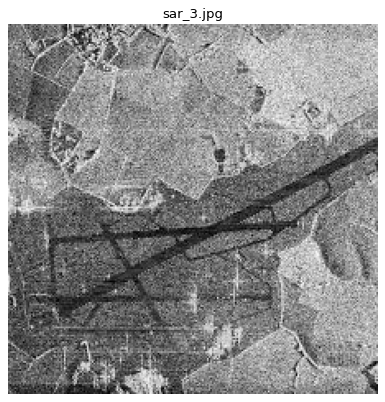

In [2]:
image = cv2.imread('sar_3.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

print("Размер (h, w):", image_gray.shape)

plt.figure(figsize=(6, 6))
plt.imshow(image_gray, cmap='gray')
plt.title("sar_3.jpg")
plt.axis('off')
plt.show()

Сглаживание → границы Canny → голосование Хафа ($\rho = x\cos\theta + y\sin\theta$). Хаф возвращает **бесконечные прямые** $(\rho, \theta)$. Чтобы найти именно **участок**, для каждой прямой берутся пиксели границ в полосе ±1.5 px от неё и ищется самая длинная цепочка с разрывами не более 10 px.\n\nСнимок радарный, в нём много спекл-шума. Сначала посмотрим, как предобработка влияет на самую сильную прямую (при одинаковых параметрах Canny(30, 90) и порога Хафа 60).

In [3]:
CANNY = (30, 90)
HOUGH_THRESHOLD = 60

smoothed = cv2.bilateralFilter(cv2.bilateralFilter(image_gray, 9, 50, 50), 9, 50, 50)

variants = [("без сглаживания", image_gray),
            ("медианный 5x5", cv2.medianBlur(image_gray, 5)),
            ("Гаусса 5x5", cv2.GaussianBlur(image_gray, (5, 5), 0)),
            ("билатеральный, 2 прохода", smoothed)]

print("{:<27}{:>14}{:>10}   {}".format("Предобработка", "пикс. границ", "прямых", "сильнейшая прямая (rho, theta)"))
for name, img in variants:
    edges = cv2.Canny(img, *CANNY)
    lines = cv2.HoughLines(edges, 1, np.pi / 180, HOUGH_THRESHOLD)
    rho, theta = lines[0][0] if lines is not None else (np.nan, np.nan)
    n = 0 if lines is None else len(lines)
    print("{:<27}{:>14}{:>10}   {:.0f}, {:.0f}°".format(name, int(np.count_nonzero(edges)), n, rho, np.degrees(theta)))

Предобработка                пикс. границ    прямых   сильнейшая прямая (rho, theta)
без сглаживания                     18839      7612   156, 45°
медианный 5x5                       12378      4257   165, 62°
Гаусса 5x5                          14575      6051   -1, 135°
билатеральный, 2 прохода             4224         7   172, 62°


Без сглаживания Canny находит около 19 тысяч пикселей границ (37 % кадра), и из них набираются случайные прямые: под углами 45° и 135° (диагонали кадра). Для дальнейшей работы берём билатеральное сглаживание.

In [4]:
def longest_edge_run(edge_pts, rho, theta, tol=1.5, gap=10):
    """Самая длинная цепочка пикселей границ вдоль прямой (rho, theta).
    Возвращает длину и концы цепочки (x1, y1, x2, y2)."""
    n = np.array([np.cos(theta), np.sin(theta)])      # нормаль к прямой
    u = np.array([-n[1], n[0]])                       # направление прямой
    near = edge_pts[np.abs(edge_pts @ n - rho) <= tol]
    if len(near) == 0:
        return 0.0, None
    t = np.sort(near @ u)
    cuts = np.where(np.diff(t) > gap)[0]
    starts, ends = np.r_[0, cuts + 1], np.r_[cuts, len(t) - 1]
    s, e = max(zip(starts, ends), key=lambda se: t[se[1]] - t[se[0]])
    p1, p2 = rho * n + t[s] * u, rho * n + t[e] * u
    return float(t[e] - t[s]), (p1[0], p1[1], p2[0], p2[1])


def seg_angle(s):
    """Угол участка к горизонтали, 0..180 градусов (против часовой стрелки)."""
    return float(np.degrees(np.arctan2(-(s[3] - s[1]), s[2] - s[0])) % 180)


edges = cv2.Canny(smoothed, *CANNY)
ys, xs = np.nonzero(edges)
edge_pts = np.stack([xs, ys], 1).astype(float)

lines = cv2.HoughLines(edges, 1, np.pi / 180, HOUGH_THRESHOLD)[:, 0]   # (rho, theta), по убыванию числа голосов
print("Прямых Хафа (порог {}): {}\n".format(HOUGH_THRESHOLD, len(lines)))

candidates = []
print("{:<4}{:>8}{:>10}{:>14}   {}".format("№", "rho", "theta", "участок, px", "концы участка (x1, y1, x2, y2)"))
for i, (rho, theta) in enumerate(lines, 1):
    length, seg = longest_edge_run(edge_pts, rho, theta)
    candidates.append((length, seg, rho, theta))
    print("{:<4}{:>8.0f}{:>9.0f}°{:>14.1f}   {}".format(i, rho, np.degrees(theta), length, tuple(int(round(v)) for v in seg)))

best_length, best_seg, best_rho, best_theta = max(candidates, key=lambda c: c[0])
bx1, by1, bx2, by2 = best_seg
print("\nСамый протяжённый участок: ({:.0f}, {:.0f}) -> ({:.0f}, {:.0f}), длина {:.1f} px, угол {:.1f}°".format(
    bx1, by1, bx2, by2, best_length, seg_angle(best_seg)))

Прямых Хафа (порог 60): 7

№        rho     theta   участок, px   концы участка (x1, y1, x2, y2)
1        172       62°          89.5   (221, 77, 142, 119)
2        165       62°         209.3   (223, 68, 39, 166)
3        164       63°         222.3   (224, 70, 26, 171)
4        171       63°          90.8   (224, 78, 143, 119)
5        174       61°          88.6   (220, 77, 143, 120)
6        167       61°         116.3   (222, 68, 121, 124)
7        135       86°          64.3   (188, 122, 124, 127)

Самый протяжённый участок: (224, 70) -> (26, 171), длина 222.3 px, угол 27.0°


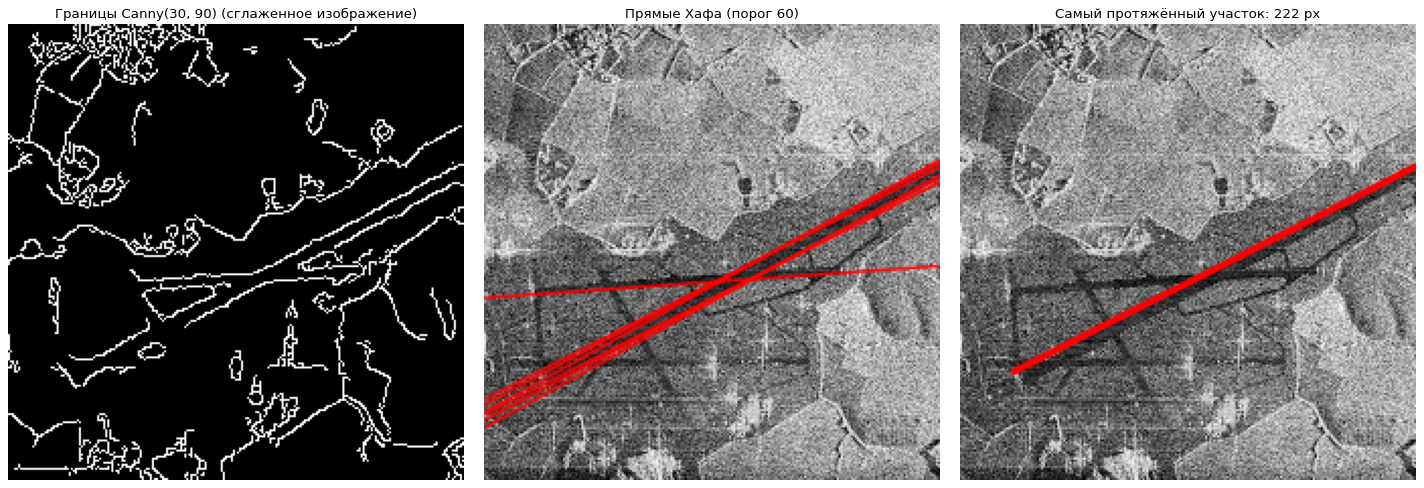

In [5]:
h, w = image_gray.shape
vis_lines = cv2.cvtColor(image_gray, cv2.COLOR_GRAY2BGR)
for rho, theta in lines:
    a, b = np.cos(theta), np.sin(theta)
    x0, y0 = a * rho, b * rho
    pt1 = (int(x0 + 1000 * (-b)), int(y0 + 1000 * a))
    pt2 = (int(x0 - 1000 * (-b)), int(y0 - 1000 * a))
    cv2.line(vis_lines, pt1, pt2, (0, 0, 255), 1, cv2.LINE_AA)

vis_seg = cv2.cvtColor(image_gray, cv2.COLOR_GRAY2BGR)
cv2.line(vis_seg, (int(round(bx1)), int(round(by1))), (int(round(bx2)), int(round(by2))), (0, 0, 255), 2, cv2.LINE_AA)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(edges, cmap='gray'); axes[0].set_title("Границы Canny{} (сглаженное изображение)".format(CANNY))
axes[1].imshow(vis_lines[:, :, ::-1]); axes[1].set_title("Прямые Хафа (порог {})".format(HOUGH_THRESHOLD))
axes[2].imshow(vis_seg[:, :, ::-1]); axes[2].set_title("Самый протяжённый участок: {:.0f} px".format(best_length))
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

**Проверка вероятностным Хафом** (`cv2.HoughLinesP`, сразу возвращает отрезки): должен найти тот же участок.

In [6]:
p_lines = cv2.HoughLinesP(edges, 1, np.pi / 180, 30, minLineLength=50, maxLineGap=10)[:, 0]
p_best = max(p_lines, key=lambda s: np.hypot(s[2] - s[0], s[3] - s[1]))
p_len = float(np.hypot(p_best[2] - p_best[0], p_best[3] - p_best[1]))
print("HoughLinesP: отрезков {}, самый длинный ({}, {}) -> ({}, {}), длина {:.1f} px, угол {:.1f}°".format(
    len(p_lines), *p_best, p_len, seg_angle(p_best)))

HoughLinesP: отрезков 11, самый длинный (41, 165) -> (222, 69), длина 204.9 px, угол 27.9°


## 2. Исследование алгоритмов бинаризации и выделение дорожной полосы

Полоса тёмная, поэтому белым помечаются пиксели **темнее** порога. Первый шаг, как в лекции, — сглаживание (используем `smoothed` из п. 1).

Критерии сравнения:
- **Белых, %** — доля пикселей маски (чем меньше, тем селективнее метод);
- **Покрытие оси, %** — доля оси полосы, попавшая в маску. Ось — найденный в п. 1 участок, смещённый поперёк на самый тёмный профиль.

Метод хорош, если покрывает ось (≥ 95 %) и даёт как можно меньше лишних белых пикселей.

In [7]:
def runway_axis(img, seg, search=20):
    """Ось полосы: участок из п. 1, смещённый по нормали туда, где средняя яркость минимальна."""
    p1 = np.array([seg[0], seg[1]], float)
    p2 = np.array([seg[2], seg[3]], float)
    u = (p2 - p1) / np.linalg.norm(p2 - p1)
    normal = np.array([-u[1], u[0]])
    t = np.linspace(0, 1, int(np.linalg.norm(p2 - p1)))[:, None]
    base = p1 + t * (p2 - p1)

    def mean_brightness(off):
        p = base + off * normal
        return ndi.map_coordinates(img.astype(float), [p[:, 1], p[:, 0]], order=1, mode='nearest').mean()

    offsets = np.arange(-search, search + 1)
    best_off = offsets[int(np.argmin([mean_brightness(o) for o in offsets]))]
    axis = base + best_off * normal
    h, w = img.shape
    inside = (axis[:, 0] >= 0) & (axis[:, 0] <= w - 1) & (axis[:, 1] >= 0) & (axis[:, 1] <= h - 1)
    return axis[inside], best_off      # точки за границей кадра отбрасываются


axis_pts, axis_offset = runway_axis(smoothed, best_seg)
print("Смещение оси от линии Хафа: {} px; яркость вдоль оси {:.1f} при средней по снимку {:.1f}".format(
    axis_offset, np.mean([smoothed[int(round(y)), int(round(x))] for x, y in axis_pts]), smoothed.mean()))


def white_percent(mask):
    return 100.0 * np.count_nonzero(mask) / mask.size


def axis_cover(mask):
    return 100.0 * np.mean([mask[int(round(y)), int(round(x))] > 0 for x, y in axis_pts])


def below(img, T):
    """Маска пикселей темнее порога (значения 0/255)."""
    return (img < T).astype(np.uint8) * 255

Смещение оси от линии Хафа: -3 px; яркость вдоль оси 58.3 при средней по снимку 130.6




- **Анализ симметричного пика гистограммы:** найти максимум гистограммы $i_{max}$; с противоположной стороны от конца найти $i_p$, для которого сумма $h_i$ от $i_p$ до конца $\ge p\%$ всех пикселей; $T = i_{max} - (i_p - i_{max})$. Гистограмма предварительно сглаживается.
- **Итеративный порог** (слайд «Расчёт T путём последовательных приближений»): $T$ — середина диапазона яркостей; $m_1$, $m_2$ — средние яркости ниже и выше $T$; $T = (m_1 + m_2)/2$; повторять, пока $T$ не перестанет меняться.
- **Адаптивная бинаризация:** порог $T$ для каждого пикселя считается по соседям в радиусе $R$ (среднее, медиана или $(I_{min}+I_{max})/2$). В лекции пиксель белый при $|I-T| > C$; для тёмного объекта берём одностороннее правило $T - I > C$, иначе белыми станут и более светлые пиксели (в таблице есть обе версии).

Дополнительно: **каскадный Оцу** — тот же метод Оцу, применённый повторно только к тёмному классу предыдущего шага. Глубина 1 — обычный Оцу.

In [8]:
def symmetric_peak_threshold(img, p, smooth=5):
    """Анализ симметричного пика гистограммы; объект темнее фона."""
    hist = np.bincount(img.ravel(), minlength=256).astype(float)
    hist = np.convolve(hist, np.ones(smooth) / smooth, mode='same')   # сглаживание гистограммы
    i_max = int(hist.argmax())
    acc, total = 0.0, hist.sum()
    for i in range(255, i_max, -1):
        acc += hist[i]
        if acc >= p / 100 * total:
            return i_max - (i - i_max)
    return i_max


def iterative_threshold(img, eps=0.5):
    """Итеративный выбор порога."""
    T = (float(img.min()) + float(img.max())) / 2
    while True:
        m1 = img[img < T].mean()
        m2 = img[img >= T].mean()
        T_new = (m1 + m2) / 2
        if abs(T_new - T) < eps:
            return T_new
        T = T_new


def cascade_otsu(img, depth):
    """Оцу, применяемый depth раз подряд к тёмному классу предыдущего шага."""
    T = 256
    for _ in range(depth):
        part = img[img < T].reshape(-1, 1)
        T, _ = cv2.threshold(part, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return int(T)


def local_threshold(img, R, stat):
    """Локальный порог по окну (2R+1)x(2R+1): среднее, медиана или (Imin+Imax)/2."""
    k = 2 * R + 1
    if stat == "mean":
        return cv2.blur(img, (k, k)).astype(np.float32)
    if stat == "median":
        return cv2.medianBlur(img, k).astype(np.float32)
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (k, k))
    return (cv2.erode(img, kernel).astype(np.float32) + cv2.dilate(img, kernel).astype(np.float32)) / 2


def adaptive_dark(img, R, C, stat, two_sided=False):
    """Адаптивная бинаризация: белый, если T - I > C (двусторонний вариант лекции: |I - T| > C)."""
    diff = local_threshold(img, R, stat) - img.astype(np.float32)
    return ((np.abs(diff) if two_sided else diff) > C).astype(np.uint8) * 255

In [9]:
T_sym1, T_sym5 = symmetric_peak_threshold(smoothed, 1), symmetric_peak_threshold(smoothed, 5)
T_tri, _ = cv2.threshold(smoothed, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_TRIANGLE)
T_otsu, _ = cv2.threshold(smoothed, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
T_iter = iterative_threshold(smoothed)
T_c2, T_c3, T_c4 = (cascade_otsu(smoothed, d) for d in (2, 3, 4))
T_c3_raw = cascade_otsu(image_gray, 3)

# (метод, параметры, маска, автоматический ли метод)
experiments = [
    ("Точечный (вручную)", "T=50",  below(smoothed, 50),  False),
    ("Точечный (вручную)", "T=70",  below(smoothed, 70),  False),
    ("Точечный (вручную)", "T=100", below(smoothed, 100), False),
    ("Симм. пик гистограммы", "p=1%, T={}".format(T_sym1), below(smoothed, T_sym1), True),
    ("Симм. пик гистограммы", "p=5%, T={}".format(T_sym5), below(smoothed, T_sym5), True),
    ("Треугольник", "T={:.0f}".format(T_tri), below(smoothed, T_tri), True),
    ("Оцу", "T={:.0f}".format(T_otsu), below(smoothed, T_otsu), True),
    ("Итеративный", "T={:.1f}".format(T_iter), below(smoothed, T_iter), True),
    ("Каскадный Оцу", "глубина 2, T={}".format(T_c2), below(smoothed, T_c2), True),
    ("Каскадный Оцу", "глубина 3, T={}".format(T_c3), below(smoothed, T_c3), True),
    ("Каскадный Оцу", "глубина 4, T={}".format(T_c4), below(smoothed, T_c4), True),
    ("Адаптивный, среднее", "R=25, C=15", adaptive_dark(smoothed, 25, 15, "mean"), True),
    ("Адаптивный, медиана", "R=25, C=15", adaptive_dark(smoothed, 25, 15, "median"), True),
    ("Адаптивный, (Imin+Imax)/2", "R=25, C=15", adaptive_dark(smoothed, 25, 15, "midrange"), True),
    ("Адаптивный, среднее", "R=10, C=10", adaptive_dark(smoothed, 10, 10, "mean"), True),
    ("Адаптивный, среднее, |I-T|>C", "R=25, C=15", adaptive_dark(smoothed, 25, 15, "mean", two_sided=True), True),
    ("Каскадный Оцу без сглаживания", "глубина 3, T={}".format(T_c3_raw), below(image_gray, T_c3_raw), True),
]

print("{:<32}{:<20}{:>10}{:>16}".format("Метод", "Параметры", "Белых, %", "Покрытие оси, %"))
rows = []
for name, params, mask, auto in experiments:
    w_, c_ = white_percent(mask), axis_cover(mask)
    rows.append((name, params, mask, auto, w_, c_))
    print("{:<32}{:<20}{:>10.1f}{:>16.1f}".format(name, params, w_, c_))

good = [r for r in rows if r[3] and r[5] >= 95 and "без сглаживания" not in r[0] and "|I-T|" not in r[0]]
winner = min(good, key=lambda r: r[4])
print("\nЛучший автоматический метод (покрытие оси >= 95%, минимум белых): {}, {}".format(winner[0], winner[1]))

Метод                           Параметры             Белых, % Покрытие оси, %
Точечный (вручную)              T=50                       0.5            11.4
Точечный (вручную)              T=70                       4.3            92.3
Точечный (вручную)              T=100                     25.4           100.0
Симм. пик гистограммы           p=1%, T=112               35.5           100.0
Симм. пик гистограммы           p=5%, T=122               42.0           100.0
Треугольник                     T=131                     47.4           100.0
Оцу                             T=127                     45.0           100.0
Итеративный                     T=127.7                   45.6           100.0
Каскадный Оцу                   глубина 2, T=93           18.5           100.0
Каскадный Оцу                   глубина 3, T=73            5.3            97.7
Каскадный Оцу                   глубина 4, T=60            2.1            57.7
Адаптивный, среднее             R=25, C=15          

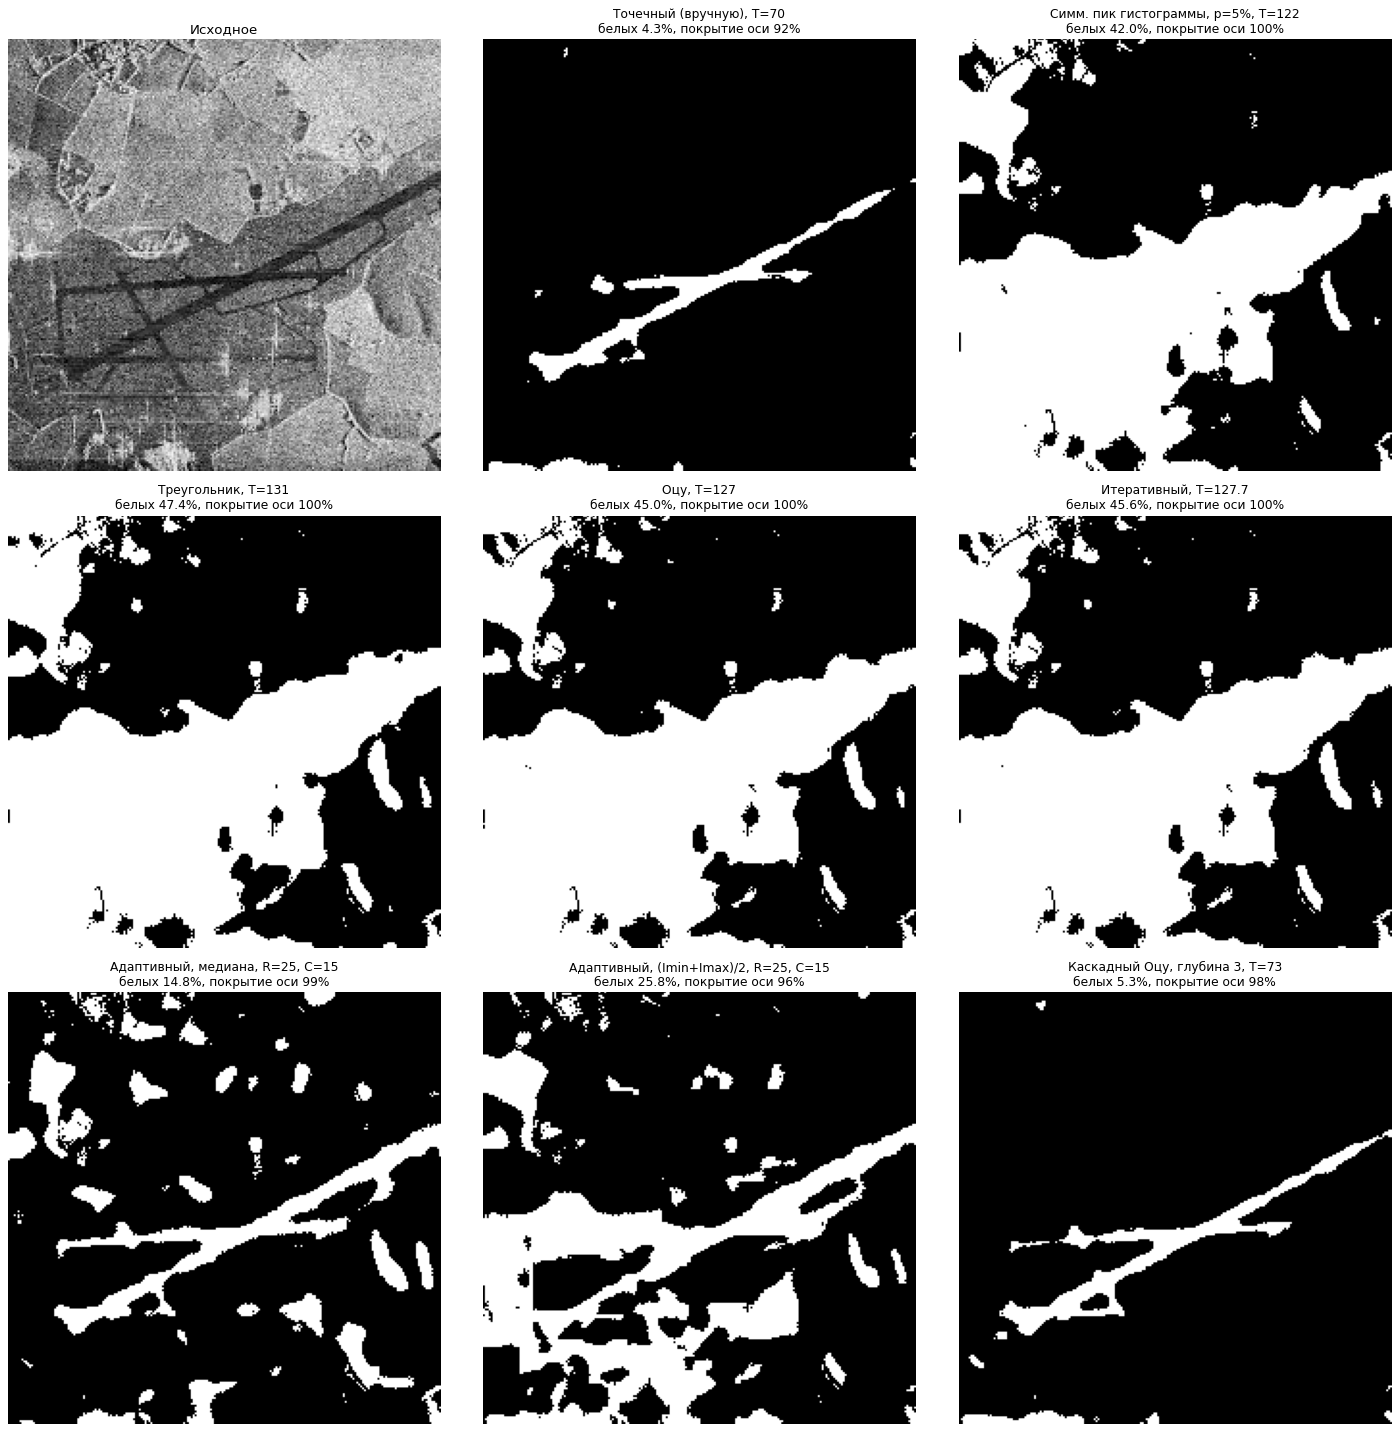

In [10]:
panel_keys = [("Точечный (вручную)", "T=70"), ("Симм. пик гистограммы", "p=5%"), ("Треугольник", None), ("Оцу", None),
              ("Итеративный", None), ("Адаптивный, медиана", None), ("Адаптивный, (Imin+Imax)/2", None),
              ("Каскадный Оцу", "глубина 3")]
panels = [next(r for r in rows if r[0] == n and (p is None or r[1].startswith(p))) for n, p in panel_keys]

fig, axes = plt.subplots(3, 3, figsize=(18, 18))
axes = axes.ravel()
axes[0].imshow(image_gray, cmap='gray'); axes[0].set_title("Исходное")
for ax, r in zip(axes[1:], panels):
    ax.imshow(r[2], cmap='gray')
    ax.set_title("{}, {}\nбелых {:.1f}%, покрытие оси {:.0f}%".format(r[0], r[1], r[4], r[5]), fontsize=11)
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

### Выделение участка дорожной полосы

Берём маску лучшего метода (каскадный Оцу, глубина 3) и обрабатываем как бинарное изображение. Открытие 3×3 убирает одиночные пиксели, закрытие 5×5 заделывает разрывы. Оставляем связные компоненты, через которые проходит ось полосы.

Порог (каскадный Оцу, глубина 3): 73
Связных компонент в очищенной маске: 9 | через ось проходит: 2
Площадь выделенной полосы: 2198 px (4.3% кадра)
Покрытие оси полосы: 96.4%


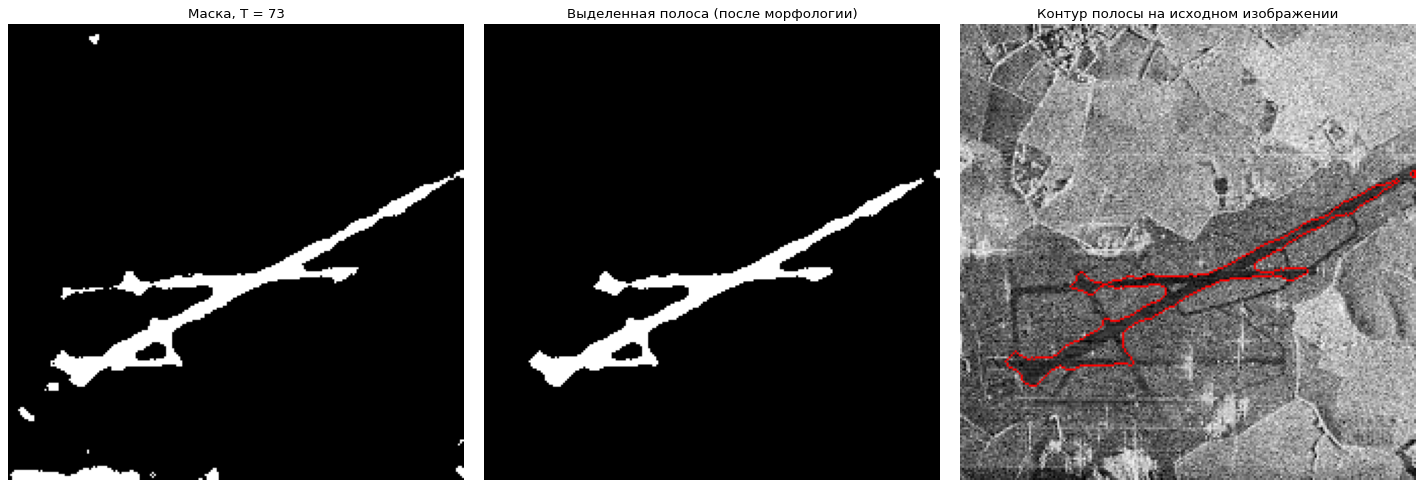

In [11]:
T_final = cascade_otsu(smoothed, 3)
mask = below(smoothed, T_final)

opened = cv2.morphologyEx(mask, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3)))
cleaned = cv2.morphologyEx(opened, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5)))

n_labels, labels, stats, _ = cv2.connectedComponentsWithStats(cleaned, connectivity=8)
on_axis = {labels[int(round(y)), int(round(x))] for x, y in axis_pts} - {0}
runway = np.isin(labels, list(on_axis)).astype(np.uint8) * 255

print("Порог (каскадный Оцу, глубина 3):", T_final)
print("Связных компонент в очищенной маске:", n_labels - 1, "| через ось проходит:", len(on_axis))
print("Площадь выделенной полосы: {} px ({:.1f}% кадра)".format(np.count_nonzero(runway), white_percent(runway)))
print("Покрытие оси полосы: {:.1f}%".format(axis_cover(runway)))

overlay = cv2.cvtColor(image_gray, cv2.COLOR_GRAY2BGR)
contours, _ = cv2.findContours(runway, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
cv2.drawContours(overlay, contours, -1, (0, 0, 255), 1)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(mask, cmap='gray'); axes[0].set_title("Маска, T = {}".format(T_final))
axes[1].imshow(runway, cmap='gray'); axes[1].set_title("Выделенная полоса (после морфологии)")
axes[2].imshow(overlay[:, :, ::-1]); axes[2].set_title("Контур полосы на исходном изображении")
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

### Проверка п. 1 по маске полосы

Длина полосы измеряется независимо от Хафа: по маске вдоль оси, пока полоса не прервётся (разрывы до 3 px допускаются).

In [12]:
def axis_run_length(mask01, axis_pts, tol_gap=3):
    """Длина непрерывного участка маски вдоль оси (ось продолжается в обе стороны до края кадра)."""
    u = (axis_pts[-1] - axis_pts[0]) / np.linalg.norm(axis_pts[-1] - axis_pts[0])
    center = axis_pts[len(axis_pts) // 2]
    h, w = mask01.shape

    def walk(sign):
        last, gap, t = 0, 0, 0
        while True:
            t += sign
            p = center + t * u
            if not (0 <= p[0] < w and 0 <= p[1] < h):
                return last
            if mask01[int(round(p[1])), int(round(p[0]))]:
                last, gap = t, 0
            else:
                gap += 1
                if gap > tol_gap:
                    return last
    return walk(1) - walk(-1)


run_len = axis_run_length(runway > 0, axis_pts)
print("Длина полосы по маске вдоль оси:                 {} px".format(run_len))
print("Участок по классическому Хафу (HoughLines):      {:.1f} px".format(best_length))
print("Участок по вероятностному Хафу (HoughLinesP):    {:.1f} px".format(p_len))

Длина полосы по маске вдоль оси:                 209 px
Участок по классическому Хафу (HoughLines):      222.3 px
Участок по вероятностному Хафу (HoughLinesP):    204.9 px


## Выводы

**1. Наиболее протяжённый участок.** Это граница взлётной полосы: отрезок (224, 70) → (26, 171), длина ≈ 222 px, угол ≈ 27° к горизонтали (классический Хаф, прямая ρ = 164, θ = 63°). Вероятностный Хаф даёт тот же участок: 205 px, угол 28°. Длина полосы по независимому измерению по маске ≈ 209 px, то есть найденные участки лежат вдоль полосы и совпадают с ней по длине в пределах 5–10 %. Две самые сильные прямые идут параллельно на расстоянии ≈ 7 px — это два края полосы шириной ≈ 8 px. На сырых и гауссово сглаженных данных Хаф ловит шумовые диагонали (45° и 135°), поэтому сглаживание перед Canny обязательно.

**2. Бинаризация.**

| Метод | Белых, % | Покрытие оси, % | Результат |
|---|---|---|---|
| Оцу, итеративный, треугольник (T ≈ 127–131) | 45–47 | 100 | непригодны: делят снимок на светлую и тёмную местность, полоса тонет в тёмной области |
| Симметричный пик гистограммы (T = 112–122) | 35–42 | 100 | то же самое: фон «симметричен» вокруг светлого пика, а полоса — малый хвост слева |
| Адаптивные: среднее, медиана, (Imin+Imax)/2 | 15–26 | 96–99 | полоса видна, но вместе со всеми локальными тёмными пятнами и текстурой; двустороннее правило abs(I−T) > C ещё хуже (33 %) |
| Точечный, T = 70 (вручную) | 4.3 | 92 | хорошо, но порог подобран вручную |
| **Каскадный Оцу, глубина 3 (T = 73)** | **5.3** | **98** | **лучший автоматический метод: порог совпал с подобранным вручную** |
| Каскадный Оцу без сглаживания | 6.0 | 59 | сглаживание обязательно |

Методы лекции (Оцу, итеративный, треугольник, симметричный пик) разделяют два крупных класса, а полоса занимает около 5 % кадра. Повторное применение Оцу к тёмному классу три раза (127 → 93 → 73) отделяет именно полосу. На глубине 4 порог падает до 60 и покрытие оси проседает до 58 %.

**Итог.** После очистки (открытие 3×3, закрытие 5×5) выделенная полоса занимает 2198 px (4.3 % кадра), маска покрывает 96 % её оси.